# Phân loại cảm xúc đánh giá phim bằng BERT

**Báo cáo thực nghiệm trên tập con dữ liệu IMDb**

### Tóm tắt

Notebook trình bày quy trình tinh chỉnh mô hình `bert-base-uncased` cho bài toán phân loại đánh giá phim tiếng Anh thành hai nhãn tích cực và tiêu cực. Thực nghiệm sử dụng 1.000 review đầu tiên của file dữ liệu IMDb trên Kaggle, gồm các bước khảo sát dữ liệu, tiền xử lý, token hóa, huấn luyện, lựa chọn checkpoint và đánh giá.

| Thành phần | Cấu hình / kết quả được lưu |
|---|---|
| Dữ liệu thực nghiệm | 1.000 review; 501 tích cực, 499 tiêu cực |
| Chia dữ liệu | 700 train / 150 validation / 150 test |
| Mô hình | `bert-base-uncased`, đầu ra 2 lớp |
| Thiết lập chính | 128 token; batch size 16; 5 epoch; learning rate `2e-5` |
| Checkpoint được chọn | Epoch 4, validation accuracy 84,00% |
| Kết quả test được lưu | Accuracy 86,00%; loss 0,3323 |

> **Phạm vi kết quả:** Các số liệu trong báo cáo được tổng hợp từ output có sẵn trong notebook, chưa được xác nhận bằng một lượt chạy mới. Chúng mô tả thí nghiệm trên tập con 1.000 review, không phải kết quả trên toàn bộ 50.000 review. Các điểm cần xử lý để chạy lại được trình bày ở mục 12.

### Nội dung báo cáo

1. Giới thiệu và phạm vi nghiên cứu
2. Cơ sở mô hình BERT
3. Dữ liệu và phân tích khám phá
4. Tiền xử lý văn bản
5. Chuẩn bị dữ liệu cho BERT
6. Khởi tạo mô hình và cấu hình huấn luyện
7. Huấn luyện và lựa chọn checkpoint
8. Đánh giá trên tập test
9. Minh họa dự đoán trên câu mới
10. Kết luận và hướng phát triển
11. Lưu trữ mô hình
12. Điều kiện tái lập và các điểm cần hoàn thiện
13. Tài liệu tham khảo

## 1. Giới thiệu và phạm vi nghiên cứu

Phân loại cảm xúc là một tác vụ xử lý ngôn ngữ tự nhiên nhằm xác định thái độ được thể hiện trong văn bản. Với đánh giá phim, bài toán có thể hỗ trợ tổng hợp phản hồi của người xem và khảo sát các yếu tố ảnh hưởng đến trải nghiệm xem phim.

Trong notebook này, đầu vào là một review tiếng Anh; đầu ra là nhãn **tích cực** (`positive`, mã 1) hoặc **tiêu cực** (`negative`, mã 0). Những nhận xét trung lập hoặc chứa nhiều cảm xúc vẫn được gán vào một trong hai lớp, vì dữ liệu thực nghiệm không có nhãn trung lập.

Mục tiêu của thực nghiệm gồm:

1. Khảo sát cấu trúc, phân bố nhãn và độ dài review trong tập dữ liệu được chọn.
2. Xây dựng quy trình chuẩn bị văn bản và đầu vào cho BERT.
3. Fine-tune bộ phân loại, lựa chọn checkpoint theo tập validation và đánh giá trên tập test.
4. Minh họa dự đoán trên một số câu mới, đồng thời phân tích giới hạn của cách triển khai.

Đây là thực nghiệm ứng dụng mô hình tiền huấn luyện. Notebook chưa thực hiện so sánh đối chứng với các phương pháp khác, nên không kết luận BERT vượt trội hơn TF-IDF, SVM hay LSTM trên tập dữ liệu này.

## 2. Cơ sở mô hình BERT

BERT (*Bidirectional Encoder Representations from Transformers*) do Devlin và cộng sự giới thiệu năm 2018, học biểu diễn văn bản dựa trên ngữ cảnh ở cả hai phía của token. Mô hình tiền huấn luyện có thể được tinh chỉnh cho các tác vụ có nhãn, trong đó có phân loại văn bản. [Bài báo BERT](https://arxiv.org/abs/1810.04805)

Thực nghiệm sử dụng checkpoint `bert-base-uncased` và lớp `BertForSequenceClassification` của thư viện Transformers.

### 2.1. Kiến trúc sử dụng

`bert-base-uncased` thuộc họ Transformer encoder, có 12 tầng encoder, kích thước biểu diễn 768 và khoảng 110 triệu tham số ở mô hình cơ sở. Phiên bản *uncased* được thiết kế cho văn bản tiếng Anh không phân biệt chữ hoa và chữ thường. [Thông tin mô hình](https://huggingface.co/google-bert/bert-base-uncased)

Trong bài toán này, một lớp phân loại được gắn vào BERT để tạo hai giá trị logits, tương ứng với hai nhãn cảm xúc. Trọng số của BERT và lớp phân loại đều được cập nhật trong quá trình fine-tuning.

### 2.2. Học chuyển tiếp và fine-tuning

Học chuyển tiếp tận dụng biểu diễn ngôn ngữ đã học trong giai đoạn tiền huấn luyện, sau đó điều chỉnh mô hình trên dữ liệu của tác vụ đích. BERT cơ sở chưa phải bộ phân loại cảm xúc; cần huấn luyện với các cặp review–nhãn để học tác vụ này.

Notebook khởi tạo BERT từ checkpoint công khai và fine-tune trên 700 review thuộc tập train. Tập validation được dùng để chọn checkpoint; tập test dành cho đánh giá sau khi lựa chọn.

### 2.3. Biểu diễn ngữ cảnh và token hóa

Cơ chế self-attention cho phép BERT kết hợp thông tin giữa các vị trí trong chuỗi. Tokenizer sử dụng WordPiece, nên một từ có thể được tách thành nhiều đơn vị nhỏ hơn. Vì vậy, từ ít gặp hoặc từ viết tắt không nhất thiết trở thành một token không xác định. [Mô tả token hóa](https://huggingface.co/google-bert/bert-base-uncased#preprocessing)

Khả năng biểu diễn này là cơ sở để lựa chọn mô hình, không phải bằng chứng cho chất lượng phân loại của một checkpoint cụ thể. Chất lượng vẫn cần được đánh giá bằng dữ liệu có nhãn.

### 2.4. Lựa chọn mô hình và giới hạn thiết kế

`bert-base-uncased` được chọn để khảo sát quy trình fine-tuning một mô hình ngôn ngữ tiền huấn luyện bằng PyTorch và Transformers. Cấu hình giới hạn chuỗi ở 128 token và batch size 16 được sử dụng trong thí nghiệm hiện tại.

Notebook chưa đo thời gian huấn luyện, bộ nhớ hay hiệu quả của các độ dài chuỗi khác nhau. Do đó, cấu hình này được xem là thiết lập thực nghiệm, chưa được xác nhận là phương án tối ưu về chất lượng hoặc tài nguyên.

## 3. Dữ liệu và phân tích khám phá

### 3.1. Nguồn dữ liệu và phạm vi lấy mẫu

Dữ liệu được tải từ [IMDb Dataset of 50K Movie Reviews trên Kaggle](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews), với định danh `lakshmi25npathi/imdb-dataset-of-50k-movie-reviews` trong KaggleHub.

Mã đọc file `IMDB Dataset.csv`, sau đó chọn **1.000 dòng đầu tiên** bằng `df.iloc[:1000, :]`. Đây là cách chọn mẫu theo thứ tự file, không phải lấy mẫu ngẫu nhiên từ toàn bộ dữ liệu. Theo output được lưu, tập con có 501 review tích cực và 499 review tiêu cực.

Mọi thống kê và kết quả tiếp theo chỉ áp dụng cho tập con này. Notebook tự chia train/validation/test sau bước chọn dữ liệu; không sử dụng một phân hoạch IMDb chuẩn được nạp riêng.

### 3.2. Tải dữ liệu và kiểm tra cấu trúc

Đoạn mã sau tải tài nguyên bằng KaggleHub, đọc dữ liệu vào DataFrame và hiển thị một số review đầu tiên. Thống kê nhãn giúp kiểm tra mức độ cân bằng của tập con trước khi huấn luyện.

Đường dẫn đọc CSV hiện được viết cố định theo môi trường Kaggle. Khi chuyển sang Colab hoặc máy cá nhân, cần lấy vị trí file từ biến `path` do `dataset_download` trả về thay vì giả định luôn có thư mục `/kaggle/input/`. [Hướng dẫn KaggleHub](https://github.com/Kaggle/kagglehub)

In [ ]:
import numpy as np
import pandas as pd
import kagglehub

# Download latest version
path = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")

print("Path to dataset files:", path)
df = pd.read_csv('/kaggle/input/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv')
df=df.iloc[:1000,:]
df.head()

Path to dataset files: /kaggle/input/imdb-dataset-of-50k-movie-reviews


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [ ]:
# Kiểm tra số lượng mỗi nhãn
print(df['sentiment'].value_counts())

sentiment
positive    501
negative    499
Name: count, dtype: int64


Hai trường dữ liệu được sử dụng trong thực nghiệm:

| Trường | Nội dung | Vai trò |
|---|---|---|
| `review` | Văn bản đánh giá phim tiếng Anh | Đầu vào của bộ phân loại |
| `sentiment` | `positive` hoặc `negative` | Nhãn gốc của dữ liệu |

Tập con gần cân bằng về số lượng hai nhãn. Tuy nhiên, cân bằng nhãn không đồng nghĩa với tính đại diện về chủ đề, độ dài hoặc cách diễn đạt của toàn bộ dataset.

### 3.3. Phân tích độ dài review

Độ dài được tính bằng số phần tử sau `str.split()`, tức số từ phân tách bởi khoảng trắng. Histogram bên dưới mô tả phân bố độ dài trong tập con đang khảo sát; đây không phải số token WordPiece sau khi đi qua BERT tokenizer.

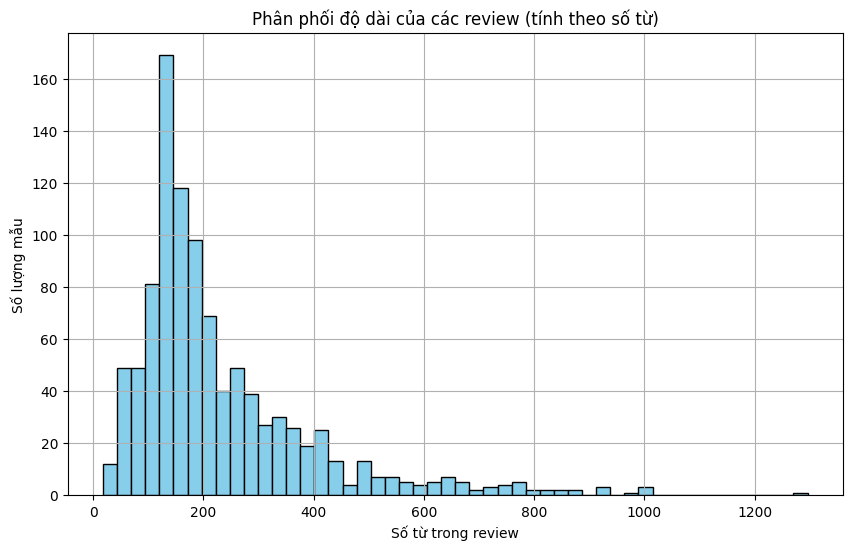

In [ ]:
import matplotlib.pyplot as plt

# Thêm cột độ dài chuỗi
df['review_length'] = df['review'].apply(lambda x: len(x.split()))

# Vẽ histogram độ dài review
plt.figure(figsize=(10,6))
plt.hist(df['review_length'], bins=50, color='skyblue', edgecolor='black')
plt.title('Phân phối độ dài của các review (tính theo số từ)')
plt.xlabel('Số từ trong review')
plt.ylabel('Số lượng mẫu')
plt.grid(True)
plt.show()


Mã token hóa sử dụng `max_length=128`. Chuỗi ngắn được bổ sung token đệm; chuỗi dài hơn giới hạn bị cắt bớt. Giới hạn này tính cả các token đặc biệt do tokenizer thêm vào.

Việc cắt chuỗi có thể loại bỏ phần nhận xét quan trọng ở cuối review. Notebook chưa thống kê tỷ lệ review bị cắt theo tokenizer, nên chưa đủ căn cứ để khẳng định 128 token bao phủ đầy đủ thông tin cảm xúc. Cần đo tỷ lệ này hoặc so sánh nhiều độ dài chuỗi trong thí nghiệm tiếp theo. [Quy tắc padding và truncation](https://huggingface.co/docs/transformers/main/pad_truncation)

### 3.4. Mã hóa nhãn

Nhãn dạng chuỗi được chuyển sang số nguyên để phù hợp với bài toán phân loại hai lớp:

| Nhãn gốc | Mã nhãn | Ý nghĩa |
|---|---|---|
| `negative` | 0 | Cảm xúc tiêu cực |
| `positive` | 1 | Cảm xúc tích cực |

Ánh xạ này cần được giữ nhất quán ở bước huấn luyện, đánh giá, dự đoán và lưu mô hình.

In [ ]:
# Chuyển sentiment (text) thành label (số)
df['label'] = df['sentiment'].map({'positive': 1, 'negative': 0})


## 4. Tiền xử lý văn bản

Hàm `preprocess_text` áp dụng các quy tắc làm sạch lên review trước khi token hóa. Các quy tắc được dùng giống nhau cho dữ liệu train, validation, test và ví dụ dự đoán.

Trong phiên bản mã hiện tại, thứ tự xử lý là: kiểm tra kiểu dữ liệu → loại thẻ HTML → loại URL → mở rộng từ viết tắt → chuyển emoji thành mô tả → chuẩn hóa khoảng trắng → chuyển về chữ thường. Việc làm sạch không mặc nhiên cải thiện chất lượng; cần kiểm tra tác động của từng quy tắc để tránh làm đổi nghĩa câu.

### 4.1. Chuẩn hóa chữ thường

Văn bản được chuyển về chữ thường ở cuối hàm tiền xử lý. Cách biểu diễn này phù hợp với lựa chọn `bert-base-uncased`. Tuy nhiên, riêng thao tác lowercasing không phải bằng chứng cho mức cải thiện accuracy của thí nghiệm.

### 4.2. Loại bỏ thẻ HTML

`BeautifulSoup(..., "html.parser").get_text()` được dùng để lấy phần văn bản, loại bỏ markup như `<br />` trong review. Cần kiểm tra đầu ra để bảo đảm ranh giới giữa các từ hoặc đoạn văn không bị mất khi bỏ thẻ.

### 4.3. Loại bỏ URL

Biểu thức chính quy loại bỏ các chuỗi được nhận diện là liên kết bắt đầu bằng `http`, `https` hoặc `www`. Mục đích là giảm nội dung địa chỉ web trong văn bản đầu vào. Notebook chưa có thí nghiệm đối chứng để lượng hóa tác động của bước này.

### 4.4. Mở rộng từ viết tắt

Hàm `expand_chat_words` tra từ điển thủ công để thay một số dạng viết tắt bằng cụm từ đầy đủ. Ví dụ, `IDK` được chuyển thành “I don’t know”. Đây là một quy tắc chuẩn hóa bổ sung, không phải yêu cầu bắt buộc của BERT tokenizer.

**Giới hạn của triển khai hiện tại:** Phép thay thế không phân biệt chữ hoa và chữ thường. Mục `TIME` trong từ điển làm từ thông thường “time” bị đổi thành “Tears in my eyes”, khiến cụm “waste of time” bị sai nghĩa. Cần rà soát các mục dễ nhập nhằng trước khi huấn luyện lại; không mặc định mọi phép thay thế đều có lợi.

### 4.5. Phạm vi xử lý lỗi chính tả

Hàm hiện tại **chưa triển khai sửa lỗi chính tả**. Các review có lỗi gõ hoặc cách viết không chuẩn được giữ lại sau các bước làm sạch khác. Nội dung này được xác định là giới hạn của phiên bản thực nghiệm, không phải một bước đã hoàn thành.

### 4.6. Chuyển emoji thành mô tả văn bản

`emoji.demojize(..., language="en")` chuyển emoji thành tên mô tả tiếng Anh. Mã tiếp tục bỏ dấu phân cách và thay dấu gạch dưới bằng khoảng trắng, nhằm giữ lại biểu hiện cảm xúc dưới dạng văn bản.

Với nhiều emoji liên tiếp, cần kiểm tra khoảng cách giữa các mô tả. Output ví dụ hiện có cho thấy hai mô tả có thể bị nối thành `crying facecrying face`.

### 4.7. Chuẩn hóa khoảng trắng và dữ liệu không hợp lệ

Các chuỗi khoảng trắng liên tiếp được rút gọn thành một dấu cách; khoảng trắng ở đầu và cuối câu được loại bỏ. Đầu vào không phải chuỗi được hàm chuyển thành chuỗi rỗng.

Khi áp dụng cho dataset khác, cần thống kê văn bản rỗng và nhãn thiếu sau tiền xử lý để tránh đưa các mẫu không hợp lệ vào huấn luyện. Notebook hiện chưa có bước thống kê riêng cho các trường hợp này.

### 4.8. Cài đặt và kiểm tra hàm tiền xử lý

Các ô mã tiếp theo cài thư viện `emoji`, định nghĩa từ điển và các hàm xử lý, sau đó minh họa trên ví dụ có HTML, URL, emoji, từ viết tắt và đầu vào không phải chuỗi. Những ví dụ này phục vụ kiểm tra hành vi của hàm, không đo chất lượng phân loại cảm xúc.

In [ ]:
pip install emoji

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 590.6/590.6 kB 5.8 MB/s eta 0:00:00


In [ ]:
import re
import emoji
import pandas as pd
from bs4 import BeautifulSoup

# Từ điển từ viết tắt/chat words
chat_word = {
    'AFAIK': 'As Far As I Know',
    'AFK': 'Away From Keyboard',
    'ASAP': 'As Soon As Possible',
    'ATK': 'At The Keyboard',
    'ATM': 'At The Moment',
    'A3': 'Anytime, Anywhere, Anyplace',
    'BAK': 'Back At Keyboard',
    'BBL': 'Be Back Later',
    'BBS': 'Be Back Soon',
    'BFN': 'Bye For Now',
    'B4N': 'Bye For Now',
    'BRB': 'Be Right Back',
    'BRT': 'Be Right There',
    'BTW': 'By The Way',
    'B4': 'Before',
    'CU': 'See You',
    'CUL8R': 'See You Later',
    'CYA': 'See You',
    'FAQ': 'Frequently Asked Questions',
    'FC': 'Fingers Crossed',
    'FWIW': "For What It's Worth",
    'FYI': 'For Your Information',
    'GAL': 'Get A Life',
    'GG': 'Good Game',
    'GN': 'Good Night',
    'GMTA': 'Great Minds Think Alike',
    'GR8': 'Great!',
    'G9': 'Genius',
    'IC': 'I See',
    'ICQ': 'I Seek you (also a chat program)',
    'ILU': 'ILU: I Love You',
    'IMHO': 'In My Honest/Humble Opinion',
    'IMO': 'In My Opinion',
    'IOW': 'In Other Words',
    'IRL': 'In Real Life',
    'KISS': 'Keep It Simple, Stupid',
    'LDR': 'Long Distance Relationship',
    'LMAO': 'Laugh My A.. Off',
    'LOL': 'Laughing Out Loud',
    'LTNS': 'Long Time No See',
    'L8R': 'Later',
    'MTE': 'My Thoughts Exactly',
    'M8': 'Mate',
    'NRN': 'No Reply Necessary',
    'OIC': 'Oh I See',
    'PPL' : 'People',
    'PD': 'My',
    'Phnx': 'Phone',
    'PLS': 'Please',
    'PITA': 'Pain In The A..',
    'PRT': 'Party',
    'PRW': 'Parents Are Watching',
    'QPSA?': 'Que Pasa?',
    'ROFL': 'Rolling On The Floor Laughing',
    'ROFLOL': 'Rolling On The Floor Laughing Out Loud',
    'ROTFLMAO': 'Rolling On The Floor Laughing My A.. Off',
    'SK8': 'Skate',
    'STATS': 'Your sex and age',
    'ASL': 'Age, Sex, Location',
    'THX': 'Thank You',
    'TTFN': 'Ta-Ta For Now!',
    'TTYL': 'Talk To You Later',
    'U': 'You',
    'U2': 'You Too',
    'U4E': 'Yours For Ever',
    'WB': 'Welcome Back',
    'WTF': 'What The F...',
    'WTG': 'Way To Go!',
    'WUF': 'Where Are You From?',
    'W8': 'Wait...',
    '7K': 'Sick:-D Laugher',
    'TFW': 'That feeling when',
    'MFW': 'My face when',
    'MRW': 'My reaction when',
    'IFYP': 'I feel your pain',
    'IDK': 'i don’t know',
    'TNTL': 'Trying not to laugh',
    'JK': 'Just kidding',
    'IDC': "I don't care",
    'ILY': 'I love you',
    'IMU': 'I miss you',
    'ADIH': 'Another day in hell',
    'ZZZ': 'Sleeping, bored, tired',
    'WYWH': 'Wish you were here',
    'TIME': 'Tears in my eyes',
    'BAE': 'Before anyone else',
    'FIMH': 'Forever in my heart',
    'BSAAW': 'Big smile and a wink',
    'BWL': 'Bursting with laughter',
    'BFF': 'Best friends forever',
    'CSL': "Can't stop laughing",
    'OMG': 'Oh my god',
    'BRB': 'Be right back',
    'BRT': 'Be right there',
    'BTW': 'By the way'
}


def expand_chat_words(text, chat_dict):
    pattern = re.compile(r'\b(' + '|'.join(re.escape(key) for key in chat_dict.keys()) + r')\b', flags=re.IGNORECASE)
    return pattern.sub(lambda x: chat_dict.get(x.group().upper(), x.group()), text)

def preprocess_text(text):
    if not isinstance(text, str):
        return ""

    # 2. Remove HTML tags
    text = BeautifulSoup(text, "html.parser").get_text()

    # 3. Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # 4. Replace chat words
    text = expand_chat_words(text, chat_word)

    # 5. Convert emojis to text
    text = emoji.demojize(text, language='en')
    text = re.sub(r':([a-zA-Z0-9_]+):', lambda m: m.group(1).replace('_', ' '), text)

    # 6. Remove excessive whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    # 1. Lowercase
    text = text.lower()


    return text


In [ ]:
examples = [
    "<br />This movie was awesome! LOL 😂 Check http://example.com for more info.",
    "IDK why ppl hate this movie. IMO, it was gr8! B4N!",
    "What a sad ending... 😢😢 #heartbreaking",
    "OMG!!! Can't wait 2 c the sequel!!! BRB, gotta watch it again.",
    "   Excessive     spaces    should be   cleaned!    ",
    None,
    12345  # Không phải chuỗi
]

for i, ex in enumerate(examples, 1):
    processed = preprocess_text(ex)
    print(f"Example {i}:\nOriginal: {ex}\nProcessed: {processed}\n{'-'*40}")

Example 1:
Original: <br />This movie was awesome! LOL 😂 Check http://example.com for more info.
Processed: this movie was awesome! laughing out loud face with tears of joy check for more info.
----------------------------------------
Example 2:
Original: IDK why ppl hate this movie. IMO, it was gr8! B4N!
Processed: i don’t know why people hate this movie. in my opinion, it was great!! bye for now!
----------------------------------------
Example 3:
Original: What a sad ending... 😢😢 #heartbreaking
Processed: what a sad ending... crying facecrying face #heartbreaking
----------------------------------------
Example 4:
Original: OMG!!! Can't wait 2 c the sequel!!! BRB, gotta watch it again.
Processed: oh my god!!! can't wait 2 c the sequel!!! be right back, gotta watch it again.
----------------------------------------
Example 5:
Original:    Excessive     spaces    should be   cleaned!    
Processed: excessive spaces should be cleaned!
----------------------------------------
Example 6:

### 4.9. Áp dụng lên tập dữ liệu

Hàm được áp dụng lên cột `review` để tạo `clean_review`. Việc đặt cạnh văn bản gốc và văn bản đã xử lý giúp phát hiện biến đổi ngoài ý muốn, đặc biệt ở các quy tắc từ viết tắt và emoji.

Trong output đang lưu, một số review chứa từ “time” đã bị thay đổi sai nghĩa. Kết quả đánh giá hiện có cần được hiểu trong bối cảnh quy trình tiền xử lý này.

In [ ]:
# Áp dụng tiền xử lý
df['clean_review'] = df['review'].apply(preprocess_text)

# Xem kết quả
print(df[['review', 'clean_review']].head())

                                              review  \
0  One of the other reviewers has mentioned that ...   
1  A wonderful little production. <br /><br />The...   
2  I thought this was a wonderful way to spend ti...   
3  Basically there's a family where a little boy ...   
4  Petter Mattei's "Love in the Time of Money" is...   

                                        clean_review  
0  one of the other reviewers has mentioned that ...  
1  a wonderful little production. the filming tec...  
2  i thought this was a wonderful way to spend te...  
3  basically there's a family where a little boy ...  
4  petter mattei's "love in the tears in my eyes ...  


## 5. Chuẩn bị dữ liệu cho BERT

### 5.1. Chia tập train, validation và test

Dataset được chia hai lần bằng `train_test_split`, với `random_state=42`:

| Phân hoạch | Số mẫu | Tỷ lệ | Mục đích |
|---|---:|---:|---|
| Train | 700 | 70% | Cập nhật trọng số mô hình |
| Validation | 150 | 15% | Theo dõi huấn luyện và chọn checkpoint |
| Test | 150 | 15% | Đánh giá sau khi chọn checkpoint |

Mã chưa sử dụng `stratify` để duy trì tỷ lệ nhãn trong từng phân hoạch và chưa kiểm tra review trùng lặp trước khi chia. `random_state=42` cố định bước chia dữ liệu, nhưng chưa bảo đảm toàn bộ quá trình huấn luyện có thể tái lập vì chưa cố định các nguồn ngẫu nhiên của mô hình và DataLoader.

In [ ]:
from sklearn.model_selection import train_test_split

# Giả sử df là DataFrame chứa cột 'text' và 'label'
train_texts, temp_texts, train_labels, temp_labels = train_test_split(
    df['clean_review'], df['label'], test_size=0.3, random_state=42)

val_texts, test_texts, val_labels, test_labels = train_test_split(
    temp_texts, temp_labels, test_size=0.5, random_state=42)

print(f"Train size: {len(train_texts)}")
print(f"Validation size: {len(val_texts)}")
print(f"Test size: {len(test_texts)}")


Train size: 700
Validation size: 150
Test size: 150


### 5.2. Token hóa và biểu diễn đầu vào

`BertTokenizer` được nạp cùng checkpoint `bert-base-uncased`. Hàm `tokenize_texts` áp dụng cùng cấu hình cho cả ba phân hoạch:

- `max_length=128`: giới hạn chiều dài chuỗi.
- `truncation=True`: cắt chuỗi vượt giới hạn.
- `padding="max_length"`: đệm đến chiều dài cố định.
- `return_tensors="pt"`: trả về tensor PyTorch.

`input_ids` biểu diễn mã token; `attention_mask` phân biệt vị trí chứa nội dung và vị trí đệm. Trong các hàm train/eval hiện tại, hai trường này được truyền vào mô hình.

Ô minh họa bổ sung bên dưới đặt `max_length=32` cho biến `encoded_samples`, nhưng phần in token dùng `tokenizer.tokenize(text)` trên toàn bộ review. Vì vậy, danh sách token được in không thể hiện việc cắt ở 32 token và không thay đổi cấu hình 128 token dùng để huấn luyện.

In [ ]:
from transformers import BertTokenizer

# Khởi tạo tokenizer từ mô hình BERT
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

# Hàm tokenization
def tokenize_texts(texts, tokenizer, max_len=128):
    return tokenizer(
        list(texts),
        padding='max_length',
        truncation=True,
        max_length=max_len,
        return_tensors='pt'
    )

# Áp dụng tokenization
train_encodings = tokenize_texts(train_texts, tokenizer)
val_encodings = tokenize_texts(val_texts, tokenizer)
test_encodings = tokenize_texts(test_texts, tokenizer)


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

In [ ]:
# Chọn một vài ví dụ từ tập train
sample_texts = train_texts.sample(3, random_state=42).tolist()

# Token hóa mà không dùng tensor, để dễ xem kết quả
encoded_samples = tokenizer(
    sample_texts,
    padding='max_length',
    truncation=True,
    max_length=32,
    return_tensors=None  # Trả về dict thông thường thay vì tensor
)

# Hiển thị kết quả tokenization
for i, text in enumerate(sample_texts):
    tokens = tokenizer.tokenize(text)
    token_ids = tokenizer.convert_tokens_to_ids(tokens)
    print(f"\n🔹 Văn bản gốc [{i+1}]:\n{text}")
    print(f"🧩 Tokenized:\n{tokens}")
    print(f"🧮 Token IDs:\n{token_ids}")



🔹 Văn bản gốc [1]:
filmfour are going to have to do a lot better than this little snot of a film if they're going to get the right sort of reputation for themselves.this film is set in glasgow (although only a couple of secondary characters have anything approaching a scottish accent). the premise, about people who's lives are going nowhere, who all meet up in the same cafe in the early hours of the morning as they have night jobs, could have made for a really funny, insightful, quirky, cultish film. instead we have a group of self-obsessed saddos and a plot which has been so done to bits i'm suprised it hasn't been banned. x and y are friends. x is sleeping with z. y sleeps with z as well. oh you figure it out.a total waste of tears in my eyes. painful dialogue - it sounded like something that a group of 16 year olds would have written for a gcse drama project. the female character was completely superfluous - just written in as a token female in the hope that women would be cajoled 

### 5.3. Xây dựng PyTorch Dataset

Lớp `IMDbDataset` ghép đầu vào đã token hóa với nhãn kiểu `torch.long`. Mỗi phần tử là một dictionary chứa các tensor đầu vào và trường `labels`, phù hợp với bộ phân loại của Transformers.

Các encoding đã ở dạng tensor; thao tác `torch.tensor(val[idx])` trong mã hiện tại tạo thêm bản sao và phát sinh cảnh báo ở output. Đây là điểm có thể tinh gọn khi chỉnh mã, không phải bằng chứng rằng quá trình huấn luyện đã thất bại.

In [ ]:
import torch

# Chuyển label sang tensor
train_labels = torch.tensor(train_labels.values, dtype=torch.long)
val_labels = torch.tensor(val_labels.values, dtype=torch.long)
test_labels = torch.tensor(test_labels.values, dtype=torch.long)

# Tạo Dataset tuỳ chỉnh
class IMDbDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = self.labels[idx]
        return item

# Tạo Dataset
train_dataset = IMDbDataset(train_encodings, train_labels)
val_dataset = IMDbDataset(val_encodings, val_labels)
test_dataset = IMDbDataset(test_encodings, test_labels)


### 5.4. Tạo DataLoader

Ba DataLoader dùng batch size 16. Tập train được xáo trộn bằng `shuffle=True`; validation và test giữ thứ tự với `shuffle=False`. Cấu hình này tách vai trò cập nhật trọng số khỏi vai trò đánh giá.

In [ ]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_dataloader = DataLoader(test_dataset, batch_size=16, shuffle=False)


## 6. Khởi tạo mô hình và cấu hình huấn luyện

### 6.1. Khởi tạo bộ phân loại hai lớp

`BertForSequenceClassification.from_pretrained` nạp phần BERT từ `bert-base-uncased` và tạo đầu ra với `num_labels=2`. Lớp phân loại được khởi tạo mới, nên cảnh báo yêu cầu huấn luyện cho tác vụ đích là phù hợp với quy trình fine-tuning.

In [ ]:
from transformers import BertForSequenceClassification

# Tải mô hình BERT với số nhãn đầu ra là 2 (positive và negative)
model = BertForSequenceClassification.from_pretrained(
    'bert-base-uncased',
    num_labels=2,  # vì bài toán phân loại nhị phân
    output_attentions=False,
    output_hidden_states=False
)


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Khi truyền `labels` vào mô hình, đầu ra cung cấp cả `loss` và `logits`. Logits dùng để suy ra nhãn bằng `argmax`; loss được dùng để cập nhật trọng số trong quá trình huấn luyện.

### 6.2. Lựa chọn thiết bị tính toán

Mã chọn GPU CUDA nếu `torch.cuda.is_available()` trả về `True`; nếu không, mô hình chạy trên CPU. Nhánh mã hiện tại không cấu hình TPU. Thiết bị và thời gian chạy thực tế chưa được ghi lại thành thông số thí nghiệm riêng.

In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)


BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

### 6.3. Bộ tối ưu và hàm mất mát

Bộ tối ưu được cấu hình là `torch.optim.AdamW`, với learning rate `2e-5` và `eps=1e-8`. Các tham số khác sử dụng mặc định của phiên bản PyTorch trong môi trường chạy.

Mặc dù mã khởi tạo biến `loss_fn = CrossEntropyLoss()`, các hàm train/eval thực tế lấy `outputs.loss` từ mô hình khi truyền `labels`. Tham số `loss_fn` được truyền vào hai hàm nhưng chưa được gọi trực tiếp trong thân hàm.

In [ ]:
from torch.optim import AdamW


optimizer = AdamW(model.parameters(), lr=2e-5, eps=1e-8)


In [ ]:
loss_fn = torch.nn.CrossEntropyLoss()


### 6.4. Lịch learning rate và cấu hình tổng hợp

Learning rate được điều chỉnh bằng scheduler tuyến tính, không có bước warm-up (`num_warmup_steps=0`). Tổng số bước được tính bằng số batch train nhân với 5 epoch; scheduler được cập nhật sau mỗi bước optimizer.

| Tham số | Giá trị |
|---|---|
| Checkpoint khởi tạo | `bert-base-uncased` |
| Số lớp | 2 |
| Chiều dài chuỗi tối đa | 128 token |
| Batch size | 16 |
| Số epoch | 5 |
| Optimizer | AdamW |
| Learning rate ban đầu | `2e-5` |
| Scheduler | Linear, 0 warm-up step |
| Tiêu chí chọn checkpoint | Validation accuracy cao nhất |

Notebook chưa khảo sát có hệ thống các tổ hợp siêu tham số, vì vậy bảng trên mô tả cấu hình đã dùng, không phải kết quả tối ưu hóa siêu tham số.

In [ ]:
from transformers import get_scheduler

epochs = 5
train_steps = len(train_dataloader) * epochs

scheduler = get_scheduler(
    name="linear",
    optimizer=optimizer,
    num_warmup_steps=0,
    num_training_steps=train_steps
)


## 7. Huấn luyện và lựa chọn checkpoint

### 7.1. Hàm huấn luyện một epoch

Hàm `train_epoch` đặt mô hình ở chế độ train, chuyển batch sang thiết bị đã chọn, tính loss, lan truyền ngược và cập nhật optimizer cùng scheduler. Giá trị trả về là trung bình loss của các batch trong epoch.

In [ ]:
def train_epoch(model, dataloader, optimizer, scheduler, loss_fn, device):
    model.train()
    total_loss = 0

    for batch in dataloader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        loss.backward()

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

    return total_loss / len(dataloader)


### 7.2. Hàm đánh giá

Hàm `eval_epoch` đặt mô hình ở chế độ eval và dùng `torch.no_grad()` để không tính gradient. Nhãn dự đoán được lấy bằng `argmax` trên logits, sau đó đối chiếu với nhãn thật để tính accuracy.

Hàm trả về trung bình loss theo batch và accuracy trên toàn bộ mẫu được duyệt. Với batch cuối nhỏ hơn, cách lấy trung bình loss hiện tại không phải trung bình có trọng số theo số mẫu.

In [ ]:
from sklearn.metrics import accuracy_score

def eval_epoch(model, dataloader, loss_fn, device):
    model.eval()
    total_loss = 0
    predictions, true_labels = [], []

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            loss = outputs.loss
            logits = outputs.logits

            total_loss += loss.item()

            preds = torch.argmax(logits, dim=1)
            predictions.extend(preds.cpu().numpy())
            true_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(true_labels, predictions)
    return total_loss / len(dataloader), acc


Kết quả validation được dùng để theo dõi diễn biến huấn luyện và lựa chọn checkpoint. Việc có tập validation giúp đánh giá quá trình học nhưng không tự bảo đảm mô hình không overfit. Tập test được giữ cho bước đánh giá sau khi đã chọn mô hình.

### 7.3. Lựa chọn và lưu checkpoint tốt nhất

Sau mỗi epoch, mã so sánh validation accuracy với giá trị tốt nhất đã ghi nhận. Khi accuracy tăng, state dict được ghi đè vào `best_model.pt`. Nếu accuracy bằng giá trị tốt nhất trước đó, checkpoint cũ được giữ lại.

Tiêu chí lựa chọn là **validation accuracy**, không phải train loss, validation loss hay test accuracy.

In [ ]:
best_acc = 0

for epoch in range(epochs):
    print(f"Epoch {epoch+1}/{epochs}")
    train_loss = train_epoch(model, train_dataloader, optimizer, scheduler, loss_fn, device)
    val_loss, val_acc = eval_epoch(model, val_dataloader, loss_fn, device)

    print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f}")

    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), 'best_model.pt')
        print("✅ Saved best model.")


<ipython-input-12-4b8dd6ae9f05>:18: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}


Epoch 1/5
Train Loss: 0.6867 | Val Loss: 0.6386 | Val Accuracy: 0.6000
✅ Saved best model.
Epoch 2/5


<ipython-input-12-4b8dd6ae9f05>:18: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}


Train Loss: 0.4919 | Val Loss: 0.3927 | Val Accuracy: 0.8067
✅ Saved best model.
Epoch 3/5


<ipython-input-12-4b8dd6ae9f05>:18: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}


Train Loss: 0.2596 | Val Loss: 0.4227 | Val Accuracy: 0.7867
Epoch 4/5


<ipython-input-12-4b8dd6ae9f05>:18: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}


Train Loss: 0.1221 | Val Loss: 0.3908 | Val Accuracy: 0.8400
✅ Saved best model.
Epoch 5/5


<ipython-input-12-4b8dd6ae9f05>:18: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}


Train Loss: 0.0818 | Val Loss: 0.4074 | Val Accuracy: 0.8333


### 7.4. Tổng hợp kết quả huấn luyện được lưu

Bảng sau được chép từ output của vòng lặp 5 epoch, không được tạo từ một lượt huấn luyện mới:

| Epoch | Train loss | Validation loss | Validation accuracy | Cập nhật checkpoint |
|---:|---:|---:|---:|---|
| 1 | 0,6867 | 0,6386 | 60,00% | Có |
| 2 | 0,4919 | 0,3927 | 80,67% | Có |
| 3 | 0,2596 | 0,4227 | 78,67% | Không |
| 4 | 0,1221 | 0,3908 | **84,00%** | **Có — checkpoint được chọn** |
| 5 | 0,0818 | 0,4074 | 83,33% | Không |

Train loss giảm qua các epoch, trong khi validation accuracy không tăng liên tục. Epoch 5 có train loss thấp hơn nhưng validation accuracy thấp hơn epoch 4; vì vậy mã giữ checkpoint của epoch 4. Diễn biến này cho thấy cần theo dõi khả năng khái quát hóa thay vì chỉ tối thiểu hóa train loss.

Notebook chưa lưu biểu đồ train/validation theo epoch; bảng trên là phần tổng hợp số liệu từ nhật ký hiện có.

## 8. Đánh giá trên tập test

### 8.1. Mục tiêu đánh giá

Tập test gồm 150 review không được dùng để cập nhật trọng số hoặc chọn checkpoint trong luồng mã hiện tại. Bước này đo mức độ dự đoán đúng trên phân hoạch test được tạo từ tập con 1.000 review.

Accuracy được tính bằng số dự đoán đúng chia cho tổng số mẫu đánh giá. Do tập test nhỏ và chưa có đánh giá qua nhiều seed, kết quả cần được diễn giải trong phạm vi của phân hoạch này.

### 8.2. Nạp checkpoint đã lựa chọn

Mô hình được nạp lại từ `best_model.pt` trước khi đánh giá. Theo nhật ký được lưu ở mục 7.4, checkpoint này tương ứng với epoch 4, thay vì trạng thái mô hình ở epoch cuối.

File chứa state dict, nên cần kiến trúc BERT hai lớp tương ứng để nạp lại. Khi chuyển môi trường hoặc thiết bị, cần kiểm tra cách ánh xạ trọng số và phiên bản thư viện.

In [ ]:
# Load lại mô hình tốt nhất
model.load_state_dict(torch.load('best_model.pt'))
model.to(device)


BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

### 8.3. Thực hiện đánh giá

`eval_epoch` được gọi với `test_dataloader` để tính test loss và test accuracy. Các giá trị được báo cáo từ output của lệnh đánh giá bên dưới; chưa có precision, recall, F1-score hoặc confusion matrix trong phiên bản mã hiện tại.

In [ ]:
# Đánh giá trên tập test
test_loss, test_acc = eval_epoch(model, test_dataloader, loss_fn, device)
print(f"\n📊 Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f}")


<ipython-input-12-4b8dd6ae9f05>:18: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}



📊 Test Loss: 0.3323 | Test Accuracy: 0.8600


### 8.4. Kết quả và phạm vi diễn giải

| Chỉ số | Giá trị từ output đã lưu |
|---|---:|
| Số mẫu test | 150 |
| Test loss | 0,3323 |
| Test accuracy | **86,00%** |

Theo accuracy được lưu, mô hình dự đoán đúng 129 trong 150 review ở phân hoạch test này. Notebook chưa lưu danh sách từng dự đoán để phân tích cụ thể 21 trường hợp sai.

Không diễn giải 86,00% như kết quả trên toàn bộ 50.000 review hoặc như mức chất lượng đã được xác nhận trên dữ liệu triển khai. Cần đánh giá lại sau khi thay đổi tiền xử lý hoặc mã chạy, đồng thời bổ sung các chỉ số theo lớp trước khi đưa ra kết luận rộng hơn.

## 9. Minh họa dự đoán trên câu mới

### 9.1. Chuẩn bị mô hình suy luận

Checkpoint `best_model.pt` được nạp lại, chuyển sang thiết bị đã chọn và đặt ở chế độ `eval()`. Các ví dụ ở phần này được viết để minh họa hành vi dự đoán, không phải một tập kiểm thử độc lập có nhãn đầy đủ.

In [ ]:
# Tải lại mô hình đã lưu
model.load_state_dict(torch.load("best_model.pt"))
model.to(device)
model.eval()


BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

### 9.2. Hàm dự đoán và cách đọc đầu ra

`predict_sentiment` token hóa một câu, chuyển tensor sang thiết bị và lấy hai điểm softmax từ logits. Nhãn có điểm lớn nhất được chọn: 0 là tiêu cực, 1 là tích cực.

Hai điểm softmax thể hiện phân bố đầu ra của mô hình; notebook chưa thực hiện hiệu chỉnh xác suất, nên không coi chúng là mức độ chắc chắn đã được kiểm chứng. Câu đầu vào cần đi qua cùng hàm tiền xử lý đã dùng cho dữ liệu huấn luyện.

In [ ]:
def predict_sentiment(text, model, tokenizer, max_len=128):
    model.eval()
    inputs = tokenizer(text, truncation=True, padding='max_length', max_length=max_len, return_tensors="pt")
    inputs = {key: val.to(device) for key, val in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.softmax(outputs.logits, dim=1)
        pred_label = torch.argmax(probs, dim=1).item()

    return pred_label, probs.cpu().numpy().flatten()


### 9.3. Ví dụ minh họa và lưu ý về khả năng chạy lại

Các câu ví dụ bao gồm nhận xét rõ cảm xúc và nhận xét pha trộn. Output đang lưu cho thấy mô hình có thể trả nhãn cho từng câu, nhưng số ví dụ ít và chưa được gán nhãn đối chiếu, nên không dùng phần này để tính thêm accuracy.

**Điểm cần sửa trong mã trước khi chạy lại:** Chữ ký hàm là `predict_sentiment(text, model, tokenizer, max_len=128)`, trong khi lời gọi bên dưới truyền `device` ở vị trí thứ tư. Tham số này sẽ được gán vào `max_len`. Lời gọi phù hợp với chữ ký hiện tại là:

```python
label, probs = predict_sentiment(cleaned, model, tokenizer, max_len=128)
```

Output cũ được giữ để đối chiếu, không chứng minh lời gọi hiện tại chạy thành công. Ngoài ra, ví dụ chứa “waste of time” đang bị quy tắc `TIME` làm đổi nghĩa như đã phân tích ở mục 4.4.

In [ ]:

# Ví dụ sử dụng:

examples = [
    "I absolutely loved this movie, it was fantastic!",
    "This was a waste of time. Very boring.",
    "Not great, but not terrible either.",
    "What a masterpiece! Would recommend to everyone.",
    "I didn't like the acting, but the story was okay."
]
# ✅ Làm sạch văn bản
clean_texts = [preprocess_text(text) for text in examples]

# ✅ Dự đoán với văn bản đã làm sạch
for original, cleaned in zip(examples, clean_texts):
    label, probs = predict_sentiment(cleaned, model, tokenizer, device)
    print(f"📝 Original Text: {original}")
    print(f"🧼 Cleaned Text: {cleaned}")
    print(f"🔮 Predicted label: {label} | Probabilities: {probs}")
    print("-" * 60)





📝 Original Text: I absolutely loved this movie, it was fantastic!
🧼 Cleaned Text: i absolutely loved this movie, it was fantastic!
🔮 Predicted label: 1 | Probabilities: [0.02871873 0.9712813 ]
------------------------------------------------------------
📝 Original Text: This was a waste of time. Very boring.
🧼 Cleaned Text: this was a waste of tears in my eyes. very boring.
🔮 Predicted label: 0 | Probabilities: [0.85947716 0.14052287]
------------------------------------------------------------
📝 Original Text: Not great, but not terrible either.
🧼 Cleaned Text: not great, but not terrible either.
🔮 Predicted label: 0 | Probabilities: [0.5986926  0.40130737]
------------------------------------------------------------
📝 Original Text: What a masterpiece! Would recommend to everyone.
🧼 Cleaned Text: what a masterpiece! would recommend to everyone.
🔮 Predicted label: 1 | Probabilities: [0.03602285 0.9639771 ]
------------------------------------------------------------
📝 Original Text: I

## 10. Kết luận và hướng phát triển

### 10.1. Kết quả đạt được

Notebook đã xây dựng quy trình fine-tuning BERT cho phân loại cảm xúc hai lớp, bao gồm chuẩn bị văn bản, token hóa, chia dữ liệu, huấn luyện, chọn checkpoint theo validation và đánh giá trên test. Trên output được lưu, epoch 4 đạt validation accuracy 84,00%; checkpoint được chọn có test accuracy 86,00% trên 150 mẫu.

Các kết quả này minh họa khả năng áp dụng một mô hình ngôn ngữ tiền huấn luyện vào bài toán phân loại review. Chúng chưa đủ để kết luận về chất lượng trên toàn bộ IMDb, trên miền dữ liệu khác hoặc về ưu thế so với mô hình đối chứng.

### 10.2. Hạn chế

- Dữ liệu thực nghiệm chỉ gồm 1.000 dòng đầu của CSV; chưa đánh giá độ đại diện của mẫu và review trùng lặp.
- Tiền xử lý từ viết tắt có thể làm sai nghĩa; việc giới hạn 128 token có thể bỏ thông tin ở cuối review.
- Chưa có đối chứng, khảo sát nhiều seed, phân tích lỗi theo lớp hay đo hiệu năng tính toán.
- Kết quả và ví dụ dự đoán đang lưu chưa được xác nhận bằng lượt chạy mới; phần demo có lời gọi hàm chưa khớp chữ ký.
- Bài toán chỉ có hai nhãn, nên câu trung lập, cảm xúc pha trộn hoặc mỉa mai có thể khó diễn giải.

### 10.3. Hướng phát triển

1. Sửa các điểm ảnh hưởng đến khả năng chạy lại, rà soát tiền xử lý, rồi huấn luyện và đánh giá lại.
2. Kiểm tra trùng lặp, lấy mẫu có chủ đích và chia dữ liệu có phân tầng theo nhãn; lưu lại phân hoạch để đối chiếu.
3. Bổ sung TF-IDF kết hợp Logistic Regression làm đối chứng; cân nhắc DistilBERT nếu cần khảo sát mô hình nhỏ hơn.
4. Báo cáo precision, recall, F1, confusion matrix, lỗi tiêu biểu và biến động kết quả qua nhiều seed.
5. Đóng gói tokenizer, cấu hình, ánh xạ nhãn và checkpoint để dùng lại trong một chương trình suy luận.

## 11. Lưu trữ mô hình

Hai ô mã cuối kết nối Google Drive trong Colab và lưu state dict vào `/content/drive/MyDrive/best_model.pt`. Phần này chỉ áp dụng khi chạy trong Google Colab và có quyền truy cập Drive tương ứng.

Ở thứ tự thực thi dự kiến, mô hình đã được nạp lại từ checkpoint tốt nhất trước khi lưu. Notebook chưa lưu tokenizer, cấu hình mô hình, phiên bản thư viện, phân hoạch dữ liệu hoặc manifest kết quả cùng state dict. Các thành phần đó cần được bổ sung khi đóng gói mô hình để sử dụng lại.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
torch.save(model.state_dict(), "/content/drive/MyDrive/best_model.pt")


## 12. Điều kiện tái lập và các điểm cần hoàn thiện

### 12.1. Môi trường và dữ liệu

Notebook sử dụng Python cùng PyTorch, Transformers, scikit-learn, pandas, NumPy, Matplotlib, KaggleHub, Beautiful Soup và emoji. Chưa có danh sách phiên bản thư viện đầy đủ được lưu kèm, nên báo cáo không giả định môi trường mới sẽ tái tạo chính xác các output hiện tại.

Cần tải được dataset Kaggle và checkpoint BERT. Các đoạn đọc dữ liệu theo `/kaggle/input/` và lưu lên Google Drive thuộc hai môi trường khác nhau; đường dẫn và thao tác lưu cần được cấu hình theo nơi thực thi. Nhánh lựa chọn thiết bị trong mã chỉ hỗ trợ CUDA hoặc CPU.

### 12.2. Trạng thái các điểm ảnh hưởng đến việc chạy lại

| Hạng mục | Trạng thái trong mã hiện tại | Việc cần thực hiện |
|---|---|---|
| Đọc CSV | Viết cố định đường dẫn Kaggle | Dùng vị trí dữ liệu thực tế do KaggleHub trả về |
| Chuẩn hóa từ viết tắt | `TIME` làm đổi nghĩa từ “time” | Rà soát hoặc loại các quy tắc nhập nhằng |
| Demo dự đoán | Truyền `device` vào vị trí `max_len` | Gọi hàm đúng chữ ký như mục 9.3 |
| Chia dữ liệu | Có `random_state=42`, chưa có `stratify` | Kiểm tra tỷ lệ nhãn và lưu phân hoạch |
| Nguồn ngẫu nhiên | Chưa cố định toàn bộ seed | Ghi lại và cố định seed khi chạy thí nghiệm mới |
| Kết quả | Đọc từ output có sẵn | Chạy lại và cập nhật sau khi chỉnh mã |
| Tài nguyên lưu mô hình | Mới có state dict trong luồng mã | Lưu thêm tokenizer, cấu hình và ánh xạ nhãn |

### 12.3. Cách sử dụng kết quả trong báo cáo

Trước khi xác nhận bản nộp có thể tái lập, cần khởi động lại kernel và chạy các ô theo thứ tự trong một môi trường đã cấu hình. Nếu sửa tiền xử lý, cần huấn luyện và đánh giá lại; không dùng nguyên kết quả 86,00% của lần chạy trước làm kết quả cho pipeline đã thay đổi.

Bản biên tập này chỉnh nội dung Markdown để phản ánh đúng mã và output đang có. Các ô code, output và metadata được giữ nguyên; việc biên tập văn bản không thay thế bước sửa lỗi thực thi hoặc chạy lại thí nghiệm.

## 13. Tài liệu tham khảo

1. Devlin, J., Chang, M.-W., Lee, K., và Toutanova, K. (2018). [BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding](https://arxiv.org/abs/1810.04805). Bài báo giới thiệu BERT; bản sửa đổi năm 2019.
2. Hugging Face. [BERT base model — uncased](https://huggingface.co/google-bert/bert-base-uncased). Thông tin checkpoint, tiền huấn luyện và token hóa.
3. Lakshmi25npathi. [IMDb Dataset of 50K Movie Reviews](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews). Nguồn CSV sử dụng trong notebook.
4. Kaggle. [KaggleHub](https://github.com/Kaggle/kagglehub). Hướng dẫn truy cập dataset và khác biệt giữa các môi trường chạy.
5. Hugging Face. [Padding and truncation](https://huggingface.co/docs/transformers/main/pad_truncation). Cấu hình chiều dài chuỗi khi token hóa.

Các tài liệu trên hỗ trợ phần mô tả phương pháp và nguồn dữ liệu. Bảng kết quả thực nghiệm trong báo cáo được tổng hợp từ output của chính notebook, không lấy từ kết quả benchmark của các tài liệu tham khảo.